<a href="https://colab.research.google.com/github/YafetG3/A01-data-wrangling/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment: Data Wrangling

### Reading material: `tidy_data.pdf`

**Q1.** This question provides some practice cleaning variables which have common problems.
1. For `./data/airbnb_hw.csv`, clean the `Price` variable as well as you can, and explain the choices you make. How many missing values do you end up with? (Hint: What happens to the formatting when a price goes over 999 dollars, say from 675 to 1,112?)
2. For the Minnesota police use of for data, `./data/mn_police_use_of_force.csv`, clean the `subject_injury` variable, handling the NA's; this gives a value `Yes` when a person was injured by police, and `No` when no injury occurred. What proportion of the values are missing? Is this a concern? Cross-tabulate your cleaned `subject_injury` variable with the `force_type` variable. Are there any patterns regarding when the data are missing?

**Q2.** Go to https://sharkattackfile.net/ and download their dataset on shark attacks (Hint: `GSAF5.xls`).

1. Open the shark attack file using Pandas. It is probably not a csv file, so `read_csv` won't work.
2. Drop any columns that do not contain data.
3. Clean the year variable. Describe the range of values you see. Filter the rows to focus on attacks since 1940. Are attacks increasing, decreasing, or remaining constant over time?
4. Clean the Age variable and make a histogram of the ages of the victims.
5. What proportion of victims are male?
6. Clean the `Type` variable so it only takes three values: Provoked and Unprovoked and Unknown. What proportion of attacks are unprovoked?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Yafet Getachew

**Date:** 9/2/26

#Question 1.1
###Choices I made include...
- First I read the file and printed the headers and their corresponding datatypes to understand the data better
- From there, I realized that the price values were stored as objects instead of integers, meaning to_numeric would fail since a comma is added once the price exceeded 999
- I then changed it so any numbers with a comma were stripped of the comma to then be translated to integers after i changed the type
###Missing values
- No missing values before or after changes
#Question 1.2
- Proportion of the values are missing = 9848 out of 12925 - Is this a concern? Yes, as around ~76% of data being missing, any conclusion we come to will only represent ~24% of cases where injury was actually recorded, which may not be properly reflect/represent the rest.
- After cross-tabulating the cleaned subject_injury variable with the force_type variable I was able to discover that injury outcomes for more severe/rare cases like firearm, gun point display, and police k9 bite have much less missing data (~0-40%) as compared to everyday/more common force types like bodily force and taser which had ~75% of missing data.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
url = 'https://raw.githubusercontent.com/YafetG3/A01-data-wrangling/main/data/airbnb_hw.csv'
df = pd.read_csv(url, low_memory=False)



print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')

df.head()

print("Missing values before:", df['Price'].isna().sum())

comma_prices = df[df['Price'].str.contains(',', na=False)]
print(comma_prices['Price'].head())

df['Price'] = df['Price'].str.replace(',', '', regex=False)
df['Price'] = df['Price'].astype('int64')

print("Missing values after:", df['Price'].isna().sum())

df.shape:
(30478, 13) 

df.dtypes:
Host Id                         int64
Host Since                     object
Name                           object
Neighbourhood                  object
Property Type                  object
Review Scores Rating (bin)    float64
Room Type                      object
Zipcode                       float64
Beds                          float64
Number of Records               int64
Number Of Reviews               int64
Price                          object
Review Scores Rating          float64
dtype: object 

Missing values before: 0
101     1,990
263     1,000
764     1,200
1272    1,000
1275    5,000
Name: Price, dtype: object
Missing values after: 0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
url = 'https://raw.githubusercontent.com/YafetG3/A01-data-wrangling/main/data/mn_police_use_of_force.csv'
df = pd.read_csv(url, low_memory=False)



print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')


df.head()

proportion_missing = df['subject_injury'].isna().mean()
print(f"Proportion Missing: {proportion_missing:.2%}" '\n')

df['subject_injury_cleaned'] = df['subject_injury'].fillna('Missing')

ct_counts = pd.crosstab(df['force_type'], df['subject_injury_cleaned'])

print("--- Raw Incident Counts ---")
print(ct_counts)

df.shape:
(12925, 13) 

df.dtypes:
response_datetime     object
problem               object
is_911_call           object
primary_offense       object
subject_injury        object
force_type            object
force_type_action     object
race                  object
sex                   object
age                  float64
type_resistance       object
precinct               int64
neighborhood          object
dtype: object 

Missing Values: 9848 out of 12925
Proportion Missing: 76.19%

--- Raw Incident Counts ---
subject_injury_cleaned       Missing    No   Yes
force_type                                      
Baton                              2     0     2
Bodily Force                    7051  1093  1286
Chemical Irritant               1421   131    41
Firearm                            0     2     0
Gun Point Display                 27    33    44
Improvised Weapon                 74    34    40
Less Lethal                       87     0     0
Less Lethal Projectile             0     

#Question 2.1
- done
#Question 2.2
- done
#Question 2.3
- After cleaning year variable, values ranged from 0 to 2026. Then, filtering for years 1940+ showed that attacks per year have increased significantly over time especially from 1940s to the 2010s. Also, it should be pointed out that although the numbers for 2020s look lower, that decade only covers ~6–7 years so far
#Question 2.4
- done
#Question 2.5
- Proportion of male victims: 80.27%
#Question 2.6
- After clean the Type variable so it only takes three values: Provoked and Unprovoked and Unknown. The proportion of unprovoked attacks came out to: 73.95%

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving GSAF5.xls to GSAF5.xls


count    7115.000000
mean     1936.549122
std       269.943193
min         0.000000
25%      1948.000000
50%      1987.000000
75%      2010.000000
max      2026.000000
Name: Year, dtype: float64


--- After Filtering for on after 1940 ---
count    5581.000000
mean     1992.668518
std        24.311209
min      1940.000000
25%      1970.000000
50%      2000.000000
75%      2013.000000
max      2026.000000
Name: Year, dtype: float64
(7117, 23)

--- Proportion of male victims ---
Proportion male: 80.27%

--- Number of each type ---
Type_clean
Unprovoked    5263
Unknown       1205
Provoked       649
Name: count, dtype: int64

--- Proportion of unprovoked ---
Proportion unprovoked (of all records): 73.95%


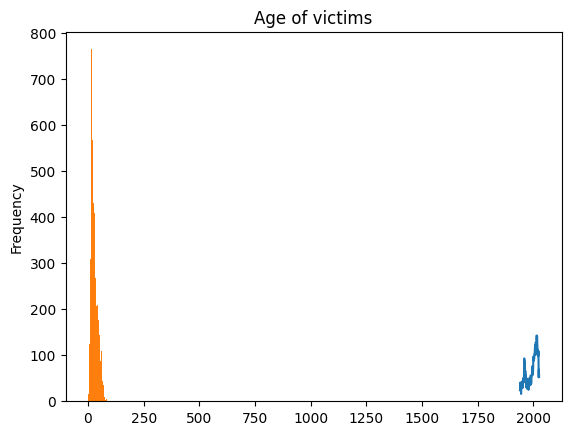

In [ ]:
import pandas as pd

df = pd.read_excel('GSAF5.xls')

df_clean = df.drop(columns=['pdf', 'href formula', 'href', 'Case Number', 'Case Number.1', 'original order', 'Unnamed: 21', 'Unnamed: 22'])

df_clean['Year'] = pd.to_numeric(df_clean['Year'], errors='coerce')
print(df_clean['Year'].describe())
print('\n')

print("--- After Filtering for on after 1940 ---")
latest = df_clean[df_clean['Year'] >= 1940]
print(latest['Year'].describe())

attacks_per_year = latest['Year'].value_counts().sort_index()
attacks_per_year.plot(kind='line', title='Shark Attacks per Year (1940+)')

print(df.shape)
df_clean.head()

df_clean['Age_clean'] = pd.to_numeric(df_clean['Age'], errors='coerce')

df_clean['Age_clean'].plot(kind='hist', bins=20, title='Age of victims')

df_clean['Sex'] = df_clean['Sex'].str.strip().str.upper()


print("\n--- Proportion of male victims ---")
prop_male = (df_clean['Sex'] == 'M').mean()
print(f"Proportion male: {prop_male:.2%}")

def clean_type(x):
    if pd.isna(x):
        return 'Unknown'
    s = str(x).strip().lower()
    if 'unprovoked' in s:
        return 'Unprovoked'
    elif 'provoked' in s:
        return 'Provoked'
    else:
        return 'Unknown'


print("\n--- Number of each type ---")
df_clean['Type_clean'] = df_clean['Type'].apply(clean_type)
print(df_clean['Type_clean'].value_counts())


print("\n--- Proportion of unprovoked ---")
prop_unprovoked = (df_clean['Type_clean'] == 'Unprovoked').mean()
print(f"Proportion unprovoked (of all records): {prop_unprovoked:.2%}")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 2af40c89c3eb7b6d3ddae503b200c9a13fcb8dc9
- **AI tool and model used:** Claude Sonnet 5 Medium

### *Prompts used

1. Using this forked repo as reference: https://github.com/YafetG3/A01-data-wrangling and the commit i pushed for phase 1, help me review and improve my code for phase 2. Phase 2: AI-assisted Revision, keep Phase 1 frozen. Phase 1 commit SHA ID: 2af40c89c3eb7b6d3ddae503b200c9a13fcb8dc9. Return a numbered list of all the recommendations/proposed changes that will be formatted like this in my response to the homework question.

2. I made a lot of similar back and forth prompts to investigate the benefits of each suggetion. For example, "what are the benefits of consolidating the repeated import numpy/matplotlib/pandas lines into a single top cell instead of repeating them in every code cell."

3. Also I asked and sent a lot of prompts to fully understand each suggestion, for example, I'd ask "expalin this suggestion in more detail: Q2.3 (Year): pd.to_numeric(errors='coerce') will null out any row where Year is stored as a range or text (e.g., "1942-1943"), silently discarding real data. Use a regex extraction (e.g., str.extract(r'(\d{4})')) to pull the first 4-digit year before converting"

### *AI-proposed changes


1. Q1.1 (Price): Verify whether Price contains a $ prefix before the numeric conversion — if so, strip both $ and , (not just ,) or the cast to int64 will silently fail/error on unstripped rows.
2. Q1.1 (Price): Use pd.to_numeric(..., errors='coerce') instead of casting straight to int64. This surfaces any value that isn't cleanly numeric (as a NaN) rather than crashing or silently mis-parsing it, and lets you report a true "missing after cleaning" count.
3. Q1.1 (Price): Add a quick df['Price'].describe() or histogram after cleaning as a sanity check that no absurd values (e.g., leftover partial commas, negative prices) slipped through.
4. Q1.2 (subject_injury): Convert the cross-tab counts to proportions with pd.crosstab(..., normalize='index') (or columns) — raw counts don't reveal the missingness rate per force_type, which is what the question is actually asking about.
5. Q2.3 (Year): pd.to_numeric(errors='coerce') will null out any row where Year is stored as a range or text (e.g., "1942-1943"), silently discarding real data. Use a regex extraction (e.g., str.extract(r'(\d{4})')) to pull the first 4-digit year before converting.
6. Q2.3 (trend claim): Support the "increasing over time" conclusion quantitatively — e.g., bin by decade and show counts/mean per decade — rather than relying only on eyeballing the line plot.
7. Q2.4 (Age): Same silent-data-loss issue as Year — raw Age values in this dataset often include text like "teens" or "10 or 12". A direct to_numeric(errors='coerce') will drop these; consider regex-extracting the first number instead, and report how many values were unrecoverable.
8. Q2.5 (Sex): After cleaning, check df_clean['Sex'].value_counts() for stray categories beyond M/F (e.g., blank strings, "lli") so the male-proportion denominator is accurate.
9. General: Consolidate the repeated import numpy/matplotlib/pandas lines into a single top cell instead of repeating them in every code cell.
10. General (reproducibility): Replace files.upload() for the shark attack file with a fixed local path (e.g., saving GSAF5.xls into ./data/) so the notebook runs end-to-end without manual intervention, consistent with how the other two datasets are loaded via URL.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | Verified that the price value doesn't have '$' prefix so no change required |
| 2 | Accept | Forgot to include 'coerce' so no hard error is thrown in case .astype('int64') comes across something it can't parse which is probably better practice even though it worked |
| 3 | Accept | Accepted becaue it's a good sanity check to look at data post chanfges to make sure nothing was incorrectly changed or not changed that should've been |
| 4 | Reject | Good in theory because it helps visualize the percentage of missing data easier but it's easier to visibly see that difference after seeing raw counts instead of percentage splits. |
| 5 | Accept | Makes sense, I didn't think to account for years that might have ranges that wouldn't get translated to integers as a result. |
| 6 | Reject | Not needed for the sake of this assignments/questions purposes. More of a nice to have then a need. |
| 7 | Accept | Same explanation as 5, better parsing to catching values that might not be picked up will be helpful for more accuracy. |
| 8 | Accept | Probably good practice to first confirm the different options (M/F/NaN/...) that exist, so denominator is accurate |
| 9 | Reject | Good suggestion but the way I was running it in my workflow (since I didn't want to import or run that cell before every block of code) I thought it'd be best to have them repeat, however, I'll take note for next few assignment  |
| 10 | Reject | Great advice and is what I wanted to do at first but couldn't figure out how to do so which is why I went with the method I did |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

df.shape:
(30478, 13) 

df.dtypes:
Host Id                         int64
Host Since                     object
Name                           object
Neighbourhood                  object
Property Type                  object
Review Scores Rating (bin)    float64
Room Type                      object
Zipcode                       float64
Beds                          float64
Number of Records               int64
Number Of Reviews               int64
Price                          object
Review Scores Rating          float64
dtype: object 

Missing values before: 0
101     1,990
263     1,000
764     1,200
1272    1,000
1275    5,000
Name: Price, dtype: object
count    30478.000000
mean       163.589737
std        197.785454
min         10.000000
25%         80.000000
50%        125.000000
75%        195.000000
max      10000.000000
Name: Price, dtype: float64


Missing values after: 0


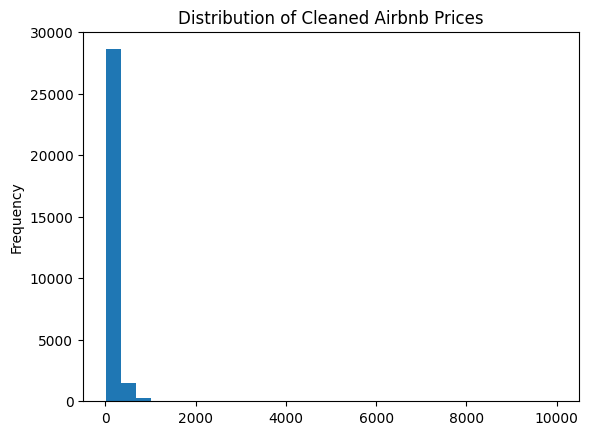

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
url = 'https://raw.githubusercontent.com/YafetG3/A01-data-wrangling/main/data/airbnb_hw.csv'
df = pd.read_csv(url, low_memory=False)



print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')

df.head()

print("Missing values before:", df['Price'].isna().sum())

comma_prices = df[df['Price'].str.contains(',', na=False)]
print(comma_prices['Price'].head())

df['Price'] = df['Price'].str.replace(',', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
print(df['Price'].describe())
print('\n')
df['Price'].plot(kind='hist', bins=30, title='Distribution of Cleaned Airbnb Prices')
df['Price'] = df['Price'].astype('int64')

print("Missing values after:", df['Price'].isna().sum())

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
url = 'https://raw.githubusercontent.com/YafetG3/A01-data-wrangling/main/data/mn_police_use_of_force.csv'
df = pd.read_csv(url, low_memory=False)



print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')

df.head()

proportion_missing = df['subject_injury'].isna().mean()
print(f"Proportion Missing: {proportion_missing:.2%}" '\n')

df['subject_injury_cleaned'] = df['subject_injury'].fillna('Missing')

ct_counts = pd.crosstab(df['force_type'], df['subject_injury_cleaned'])

print("--- Raw Incident Counts ---")
print(ct_counts)

df.shape:
(12925, 13) 

df.dtypes:
response_datetime     object
problem               object
is_911_call           object
primary_offense       object
subject_injury        object
force_type            object
force_type_action     object
race                  object
sex                   object
age                  float64
type_resistance       object
precinct               int64
neighborhood          object
dtype: object 

Proportion Missing: 76.19%

subject_injury
NaN    9848
Yes    1631
No     1446
Name: count, dtype: int64
--- Raw Incident Counts ---
subject_injury_cleaned       Missing    No   Yes
force_type                                      
Baton                              2     0     2
Bodily Force                    7051  1093  1286
Chemical Irritant               1421   131    41
Firearm                            0     2     0
Gun Point Display                 27    33    44
Improvised Weapon                 74    34    40
Less Lethal                       87     0     

In [4]:
from google.colab import files
uploaded = files.upload()

Saving GSAF5.xls to GSAF5.xls


Series([], Name: count, dtype: int64)
count    6984.000000
mean     1972.861541
std        51.074438
min      1000.000000
25%      1951.000000
50%      1988.000000
75%      2010.000000
max      2026.000000
Name: Year, dtype: float64


--- After Filtering for on after 1940 ---
count    5581.000000
mean     1992.668518
std        24.311209
min      1940.000000
25%      1970.000000
50%      2000.000000
75%      2013.000000
max      2026.000000
Name: Year, dtype: float64
(7117, 23)
Still missing after targeted recovery: 3124

--- Sex value counts after cleaning ---
Sex
M        5713
F         818
NaN       578
?           2
N           2
M F         1
LLI         1
M X 2       1
.           1
Name: count, dtype: int64

--- Proportion of male victims ---
Proportion male: 80.27%

--- Number of each type ---
Type_clean
Unprovoked    5263
Unknown       1205
Provoked       649
Name: count, dtype: int64

--- Proportion of unprovoked ---
Proportion unprovoked (of all records): 73.95%


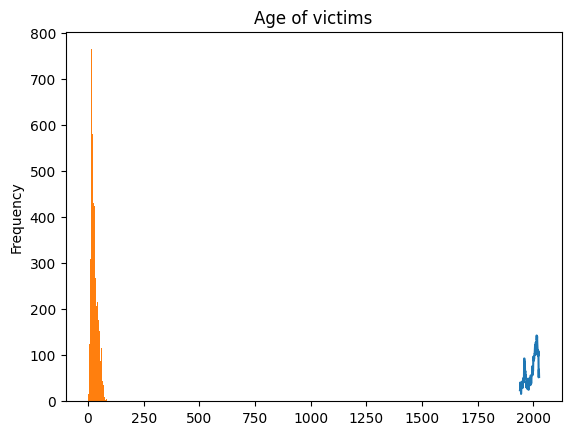

In [5]:
import pandas as pd

df = pd.read_excel('GSAF5.xls')

#df_clean = df.drop(columns=['pdf', 'href formula', 'href', 'Case Number', 'Case Number.1', 'original order', 'Unnamed: 21', 'Unnamed: 22'])
df_clean = df.dropna(axis=1, how='all')

year_numeric = pd.to_numeric(df['Year'], errors='coerce')
lost_rows = df.loc[year_numeric.isna() & df['Year'].notna(), 'Year']
print(lost_rows.value_counts().head(20))
df_clean['Year'] = df_clean['Year'].astype(str).str.extract(r'(\d{4})').astype(float)
print(df_clean['Year'].describe())
print('\n')

print("--- After Filtering for on after 1940 ---")
latest = df_clean[df_clean['Year'] >= 1940]
print(latest['Year'].describe())

attacks_per_year = latest['Year'].value_counts().sort_index()
attacks_per_year.plot(kind='line', title='Shark Attacks per Year (1940+)')

print(df.shape)
df_clean.head()

age_str = df_clean['Age'].astype(str).str.strip()

# Only recover clean decade patterns like "30s", "20's", "40+"
decade_match = age_str.str.extract(r'^(\d{2})(?:s|\'s|\+)$')[0]

df_clean['Age_clean'] = pd.to_numeric(df_clean['Age'], errors='coerce')
df_clean['Age_clean'] = df_clean['Age_clean'].fillna(pd.to_numeric(decade_match))

print("Still missing after targeted recovery:", df_clean['Age_clean'].isna().sum())

df_clean['Age_clean'].plot(kind='hist', bins=20, title='Age of victims')

df_clean['Sex'] = df_clean['Sex'].str.strip().str.upper()

print("\n--- Sex value counts after cleaning ---")
print(df_clean['Sex'].value_counts(dropna=False))

print("\n--- Proportion of male victims ---")
prop_male = (df_clean['Sex'] == 'M').mean()
print(f"Proportion male: {prop_male:.2%}")

def clean_type(x):
    if pd.isna(x):
        return 'Unknown'
    s = str(x).strip().lower()
    if 'unprovoked' in s:
        return 'Unprovoked'
    elif 'provoked' in s:
        return 'Provoked'
    else:
        return 'Unknown'


print("\n--- Number of each type ---")
df_clean['Type_clean'] = df_clean['Type'].apply(clean_type)
print(df_clean['Type_clean'].value_counts())


print("\n--- Proportion of unprovoked ---")
prop_unprovoked = (df_clean['Type_clean'] == 'Unprovoked').mean()
print(f"Proportion unprovoked (of all records): {prop_unprovoked:.2%}")

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]


There were a lot of good improvements suggested by the ai that caught real problems I hadn't considered and was much more thorough. The clearest example of this being the Year and Age columns as I had intially used pd.to_numeric (errors='coerce') for both. However, I didn't take into account that this could silently overlook important data that wouldn't be caught when parsing. Data like "1942-1943" or "10 or 12", which shouldn't be discarded but would in the method I used since it's not formatted the way the function expects.

Another imrovement the AI recommended which I missed is to thoroughly check value_counts() on columns like Sex and subject_injury. I had assumed cleaning with .str.strip().str.upper() was enough, but that I realized that doesn't guarantee only the categories I expect (M/F) actually exist and verifying first, makes any further cleaning a lot easier to trust.

Although a limitation I dicovered was how the ai overcomplicated simple tasks.  Suggetions like "consolidating imports into one cell", were reasonable I tested general practices but didn't observe any significant changes. I believe when using AI, especially for data wrangling, it's important to compare outputs before and after and only accept changes that fixed real accuracy issues, and rejected ones that only added polish without changing correctness.

